# 01 · Exploratory analysis — Cleveland heart-disease data

**Goal of this notebook:** understand the 303 Cleveland patients well enough to (1) justify the
cleaning rules in `src/heart/data.py`, (2) decide which columns are numeric vs. nominal, and
(3) motivate the two engineered features in `src/heart/features.py`.

All figures are written to `reports/figures/` so the report and README can reuse them.
Run `python scripts/download_data.py` first.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from heart import config
from heart.data import clean, load_raw
from heart.features import add_derived_features

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
PALETTE = {0: "#5dade2", 1: "#e74c3c"}

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=130)
    print("saved", (FIG / name).relative_to(ROOT))

raw = load_raw(ROOT / "data/raw/cleveland_raw.csv")
df = clean(raw)
print("raw:", raw.shape, " clean:", df.shape)
raw.head()

raw: (303, 14)  clean: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Data quality check

In [2]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isna().sum(),
    "n_unique": raw.nunique(),
    "min": raw.min(), "max": raw.max(),
})
summary

,dtype,n_missing,n_unique,min,max
age,float64,0,41,29.0,77.0
sex,float64,0,2,0.0,1.0
cp,float64,0,4,1.0,4.0
trestbps,float64,0,50,94.0,200.0
chol,float64,0,152,126.0,564.0
fbs,float64,0,2,0.0,1.0
restecg,float64,0,3,0.0,2.0
thalach,float64,0,91,71.0,202.0
exang,float64,0,2,0.0,1.0
oldpeak,float64,0,40,0.0,6.2


In [3]:
# The rows that carry a '?' in the original file
raw[raw[["ca", "thal"]].isna().any(axis=1)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


### Cleaning decisions (implemented in `heart.data.clean`)

* **Only 6 of 303 rows are incomplete** - 4 have `ca` = '?' and 2 have `thal` = '?'. No row is missing both, and the six rows are a mix of healthy and diseased patients, so there is no sign the gaps are tied to the outcome.
* **I keep these rows and impute inside the model pipeline** instead of dropping them or filling them in the CSV: `ca` gets the training-fold median (0 vessels) and `thal` gets the training-fold mode (normal). Dropping would throw away 2% of an already small sample. Imputing in the pipeline means the imputer only ever sees training folds, so nothing leaks into CV or test scores. It also means the deployed API can still score a patient whose fluoroscopy or thallium result is not available yet.
* **Types:** every column is parsed as numeric. Coded columns are validated against the UCI codebook (for example `thal` must be in {3, 6, 7}), and any out-of-domain code becomes NaN and goes through the same imputation path. Nothing was out of domain in this file, so the check is a safeguard for future inputs.
* **Target:** `num` grades severity from 0 to 4. Grades 1-4 are rare individually (see below), so they are collapsed into one 'disease present' class, matching how the original Cleveland studies used the data.
* **Column roles:** `cp`, `restecg`, `slope` and `thal` are nominal codes, so they are one-hot encoded. `sex`, `fbs` and `exang` are already 0/1. `ca` is a count of vessels (0-3), so it stays numeric. Its disease rate rises almost monotonically with the count, so a single slope captures it.
* There are no exact duplicate rows in the raw file.

## 2. Target: severity grade vs. binary label

saved reports\figures\class_balance.png


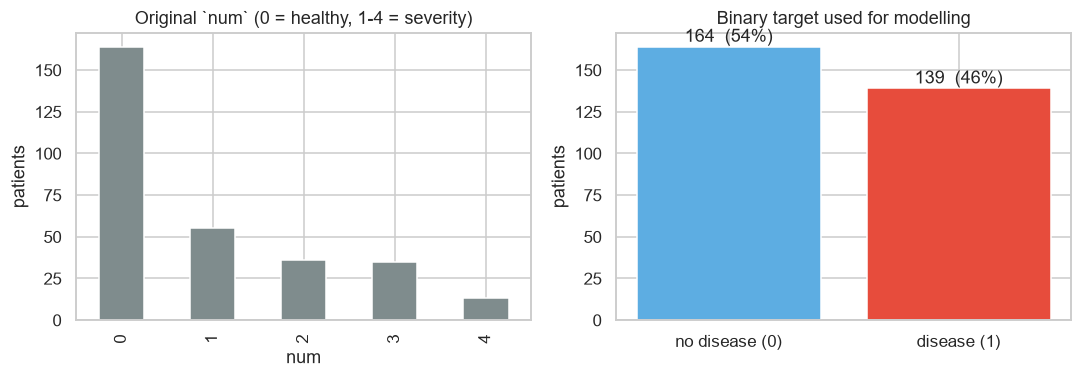

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
raw["num"].value_counts().sort_index().plot.bar(ax=axes[0], color="#7f8c8d")
axes[0].set(title="Original `num` (0 = healthy, 1-4 = severity)", xlabel="num", ylabel="patients")
counts = df[config.TARGET].value_counts().sort_index()
axes[1].bar(["no disease (0)", "disease (1)"], counts.values, color=[PALETTE[0], PALETTE[1]])
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 3, f"{v}  ({v/len(df):.0%})", ha="center")
axes[1].set(title="Binary target used for modelling", ylabel="patients")
fig.tight_layout(); save(fig, "class_balance.png"); plt.show()

**Class balance.** After binarisation there are 164 healthy and 139 diseased patients (54% / 46%). That is close enough to balanced that I do not resample. I still test `class_weight='balanced'` in the grid search, and every split is stratified so each fold keeps the 46% positive rate. The severity grades 1-4 range from 13 to 55 patients each, which is too few to model as separate classes.

## 3. Numeric features — distributions split by outcome

saved reports\figures\numeric_hist_by_target.png


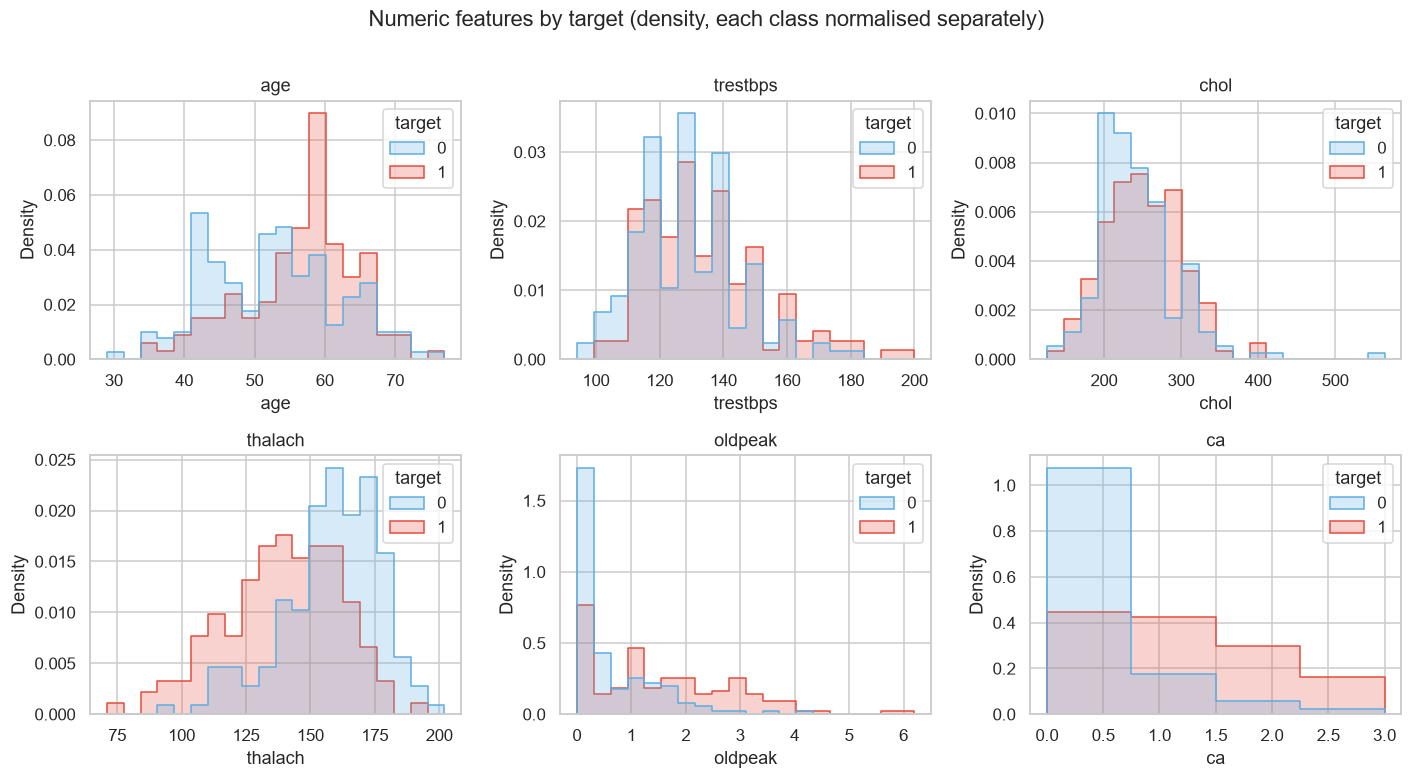

target,median_no_disease,median_disease
age,52.0,58.0
trestbps,130.0,130.0
chol,234.5,249.0
thalach,161.0,142.0
oldpeak,0.2,1.4
ca,0.0,1.0


In [5]:
num_cols = config.NUMERIC_COLS
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue=config.TARGET, palette=PALETTE, element="step",
                 stat="density", common_norm=False, bins=20 if col != "ca" else 4, ax=ax)
    ax.set_title(col)
fig.suptitle("Numeric features by target (density, each class normalised separately)", y=1.01)
fig.tight_layout(); save(fig, "numeric_hist_by_target.png"); plt.show()

df.groupby(config.TARGET)[num_cols].median().T.rename(columns={0: "median_no_disease", 1: "median_disease"})

**What the numeric histograms show**

* `thalach` (peak exercise heart rate) and `oldpeak` (ST depression) separate the classes the most. Diseased patients peak about 19 bpm lower (median 142 vs 161), and their ST depression median is 1.4 mm against 0.2 mm. `oldpeak` has a big spike at 0, so most healthy patients show no depression at all.
* `ca` is just as telling: most healthy patients have 0 coloured vessels, while the diseased group spreads across 1-3.
* Resting blood pressure has the same median (130) in both groups, and cholesterol only shifts by about 15 mg/dl. Both matter much less than the textbook risk-factor view suggests, which is likely because these are already-referred patients and many were on treatment.
* `chol` (up to 564) and `oldpeak` are right-skewed. Tree models do not care. For logistic regression, standardising was enough in practice, so I did not log-transform them, which keeps the feature list easy to explain in the API.

## 4. Categorical / binary features — disease rate per level

saved reports\figures\categorical_target_rate.png


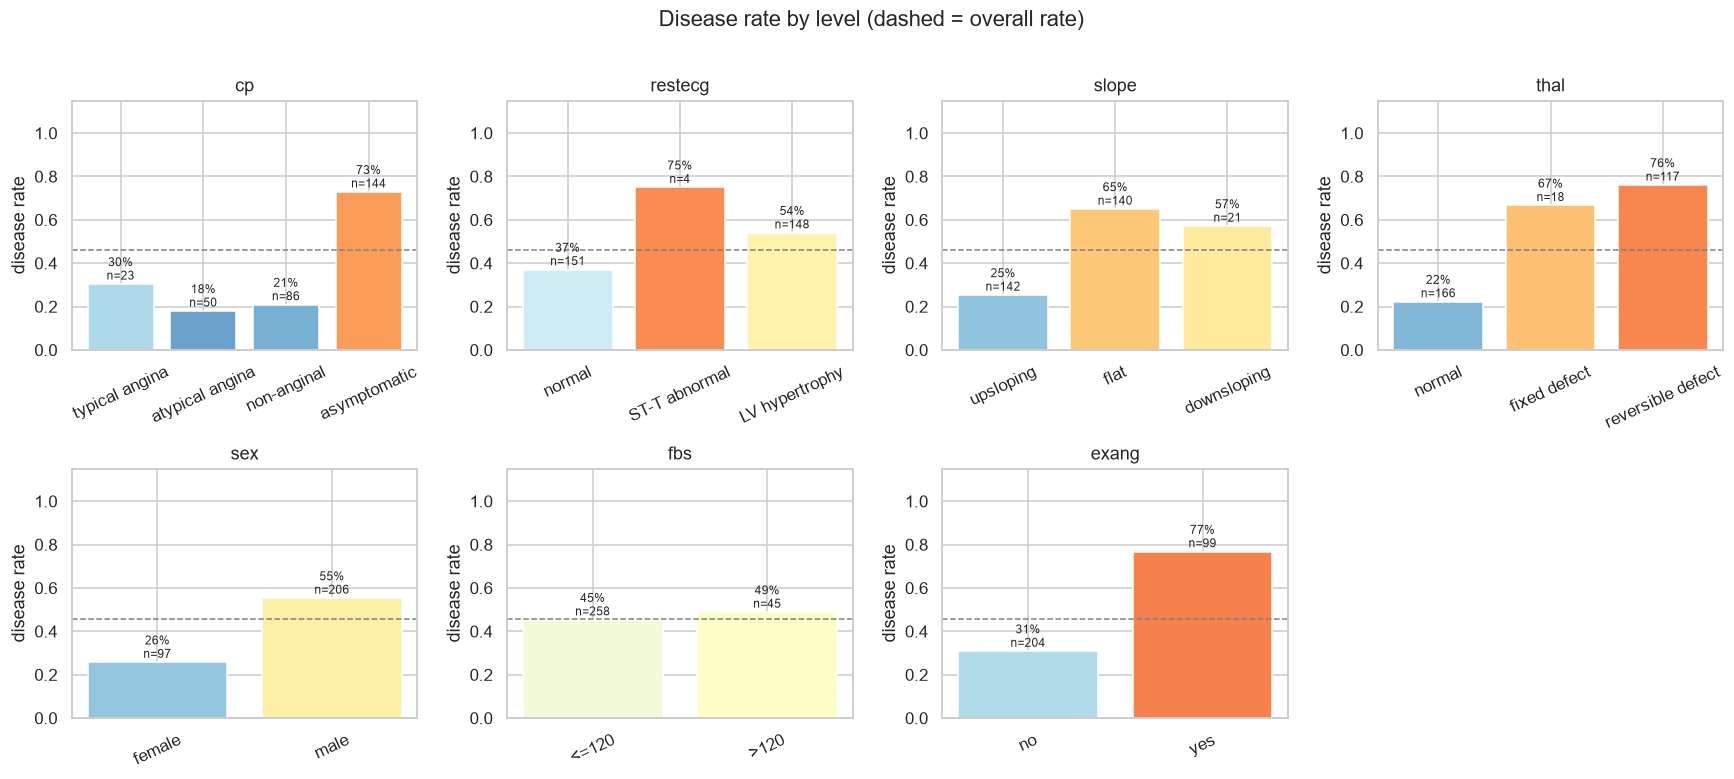

In [6]:
labels = {
    "cp": {1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"},
    "restecg": {0: "normal", 1: "ST-T abnormal", 2: "LV hypertrophy"},
    "slope": {1: "upsloping", 2: "flat", 3: "downsloping"},
    "thal": {3: "normal", 6: "fixed defect", 7: "reversible defect"},
    "sex": {0: "female", 1: "male"}, "fbs": {0: "<=120", 1: ">120"}, "exang": {0: "no", 1: "yes"},
}
cat_cols = config.CATEGORICAL_COLS + config.BINARY_COLS
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    g = df.groupby(col)[config.TARGET].agg(["mean", "size"]).reset_index()
    g["level"] = g[col].map(labels[col])
    ax.bar(g["level"], g["mean"], color=plt.cm.RdYlBu_r(g["mean"]))
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.02, f"{m:.0%}\nn={n}", ha="center", fontsize=8)
    ax.axhline(df[config.TARGET].mean(), ls="--", c="grey", lw=1)
    ax.set(title=col, ylim=(0, 1.15), ylabel="disease rate")
    ax.tick_params(axis="x", rotation=25)
axes.ravel()[-1].axis("off")
fig.suptitle("Disease rate by level (dashed = overall rate)", y=1.01)
fig.tight_layout(); save(fig, "categorical_target_rate.png"); plt.show()

**Categorical levels**

* **Asymptomatic chest pain (cp = 4) is the high-risk group, with 73% diseased.** Patients reporting typical or atypical angina have rates of only 18-30%. It looks backwards, but it makes sense in a referral cohort: people with silent ischaemia were found through other tests and sent for angiography.
* **Exercise-induced angina** (`exang` = 1) has a 77% rate against 31% without, and a **flat or downsloping ST segment** is 57-65% against 25% for upsloping.
* **Fasting blood sugar adds almost nothing** (45% vs 49%). I keep it because it costs nothing in the pipeline, and the regularised models can shrink it.
* `restecg` = 1 has only 4 patients. A CV fold can easily lack this level entirely, which is exactly why the encoder uses `handle_unknown='ignore'`.

## 5. Correlation structure

saved reports\figures\correlation_heatmap.png


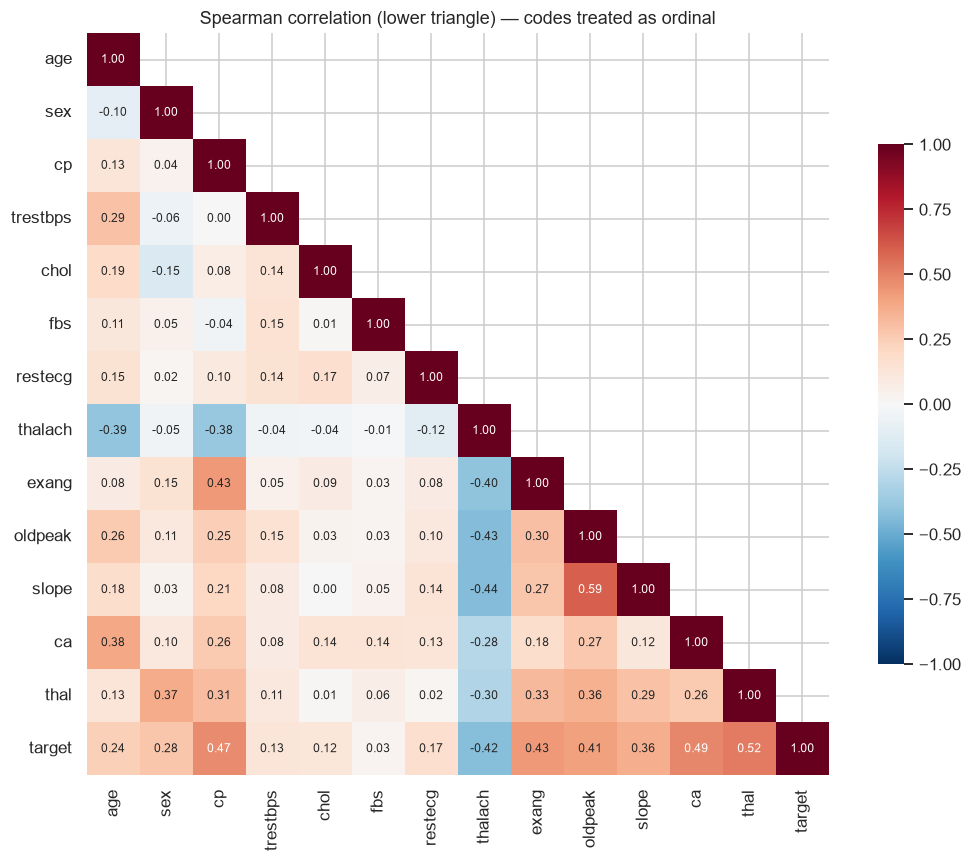

,rho_with_target
thal,0.522
ca,0.489
cp,0.472
exang,0.432
thalach,-0.423
oldpeak,0.413
slope,0.364
sex,0.277
age,0.237
restecg,0.169


In [7]:
corr = df.astype(float).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7}, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation (lower triangle) — codes treated as ordinal")
fig.tight_layout(); save(fig, "correlation_heatmap.png"); plt.show()

corr[config.TARGET].drop(config.TARGET).sort_values(key=np.abs, ascending=False).round(3).to_frame("rho_with_target")

**Correlation.** I used Spearman rather than Pearson because half the columns are ordinal codes. The strongest links to the target are `thal` (0.52), `ca` (0.49), `cp` (0.47), `exang` (0.43), `thalach` (-0.42) and `oldpeak` (0.41). These come from the stress test and imaging rather than from demographics. Among the features, the largest pairs are `oldpeak`-`slope` (0.59), `thalach`-`slope` (-0.44), `cp`-`exang` (0.43) and `thalach`-`oldpeak` (-0.43). They are moderate, all within |0.6|, so multicollinearity is not severe enough to drop anything. L2 regularisation in the logistic model takes care of the rest.

## 6. Own question A — does chest-pain type interact with thallium result?

saved reports\figures\cp_thal_interaction.png


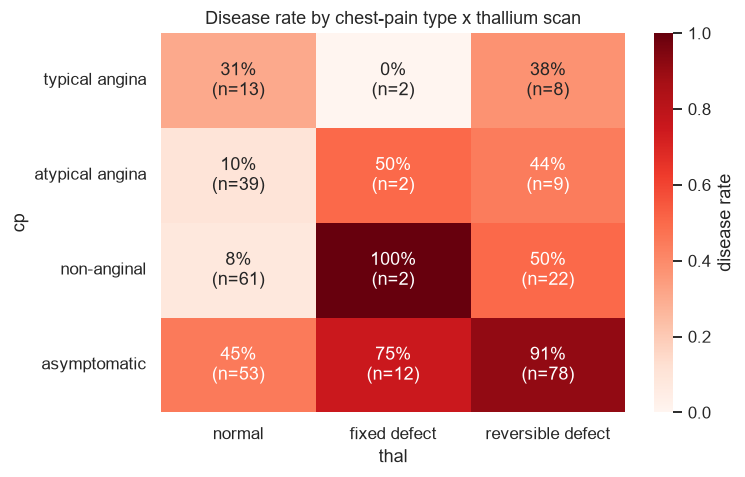

In [8]:
pivot_rate = df.pivot_table(index="cp", columns="thal", values=config.TARGET, aggfunc="mean")
pivot_n = df.pivot_table(index="cp", columns="thal", values=config.TARGET, aggfunc="size")
pivot_rate.index = pivot_rate.index.map(labels["cp"]); pivot_rate.columns = pivot_rate.columns.map(labels["thal"])
annot = pivot_rate.map(lambda v: "" if pd.isna(v) else f"{v:.0%}") + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str).values + ")"
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(pivot_rate, annot=annot.values, fmt="", cmap="Reds", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "disease rate"})
ax.set(title="Disease rate by chest-pain type x thallium scan", xlabel="thal", ylabel="cp")
fig.tight_layout(); save(fig, "cp_thal_interaction.png"); plt.show()

**Insight A: chest pain and thallium are partly redundant, but they reinforce each other at the top end.**
With a normal thallium scan, even asymptomatic patients sit at 45%, and the non-anginal group is only 8%. Combine asymptomatic pain with a *reversible* defect (78 patients, the largest high-risk cell) and the rate jumps to 91%. A model that adds these effects separately would underestimate that corner. This is one reason I compare against tree ensembles, which can pick up the interaction without hand-made cross features. The fixed-defect column has only 2-12 patients per cell, so I don't read anything into those percentages.

## 7. Own question B — age and sex together

mean         size     
sex_lbl  female  male female male
age_band                         
29-45      0.06  0.33     18   45
46-55      0.12  0.48     26   62
56-65      0.50  0.68     40   79
66-77      0.08  0.75     13   20

saved reports\figures\age_sex_risk.png


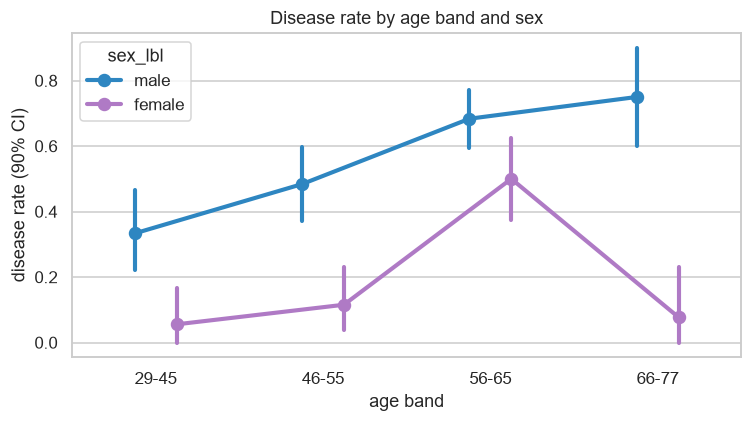

In [9]:
bands = pd.cut(df["age"], bins=[28, 45, 55, 65, 80], labels=["29-45", "46-55", "56-65", "66-77"])
age_sex = df.assign(age_band=bands, sex_lbl=df["sex"].map(labels["sex"]))
tbl = age_sex.groupby(["age_band", "sex_lbl"], observed=True)[config.TARGET].agg(["mean", "size"]).unstack()
display(tbl.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=age_sex, x="age_band", y=config.TARGET, hue="sex_lbl", dodge=0.25,
              palette={"female": "#af7ac5", "male": "#2e86c1"}, errorbar=("ci", 90), ax=ax)
ax.set(ylabel="disease rate (90% CI)", xlabel="age band", title="Disease rate by age band and sex")
fig.tight_layout(); save(fig, "age_sex_risk.png"); plt.show()

**Insight B: sex changes the age effect dramatically.**
The male disease rate climbs steadily, from 33% (29-45) to 75% (66-77). The female rate stays low (6-12%) until 56-65, where it jumps to 50%, which fits the usual post-menopausal shift. It then drops back for the 13 women over 65. That last group is small, but it suggests the women referred late in life were often referred for other reasons. Overall, being male roughly doubles the rate (55% vs 26%). Because the age effect is not linear and differs by sex, I prefer models that can bend (Random Forest, gradient boosting), or at least keep `sex` as an explicit input to the linear model.

## 8. Checking the engineered features before using them

saved reports\figures\engineered_features.png


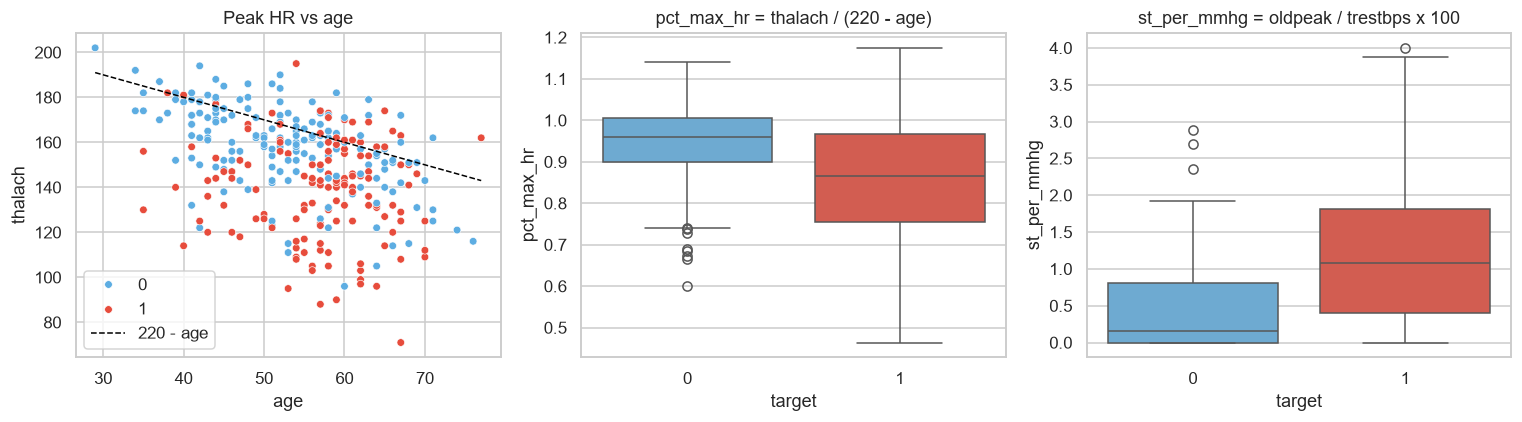

,single-feature AUC
thalach,0.745
pct_max_hr,0.699
oldpeak,0.735
st_per_mmhg,0.734


In [10]:
eng = add_derived_features(df[config.FEATURE_COLS].astype(float)).assign(target=df[config.TARGET])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.scatterplot(data=eng, x="age", y="thalach", hue="target", palette=PALETTE, ax=axes[0], s=25)
a = np.linspace(29, 77, 10); axes[0].plot(a, 220 - a, "k--", lw=1, label="220 - age")
axes[0].legend(); axes[0].set_title("Peak HR vs age")
sns.boxplot(data=eng, x="target", y="pct_max_hr", hue="target", palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("pct_max_hr = thalach / (220 - age)")
sns.boxplot(data=eng, x="target", y="st_per_mmhg", hue="target", palette=PALETTE, legend=False, ax=axes[2])
axes[2].set_title("st_per_mmhg = oldpeak / trestbps x 100")
fig.tight_layout(); save(fig, "engineered_features.png"); plt.show()

from sklearn.metrics import roc_auc_score
pd.Series({c: roc_auc_score(eng.target, -eng[c] if c in ("thalach", "pct_max_hr") else eng[c])
           for c in ["thalach", "pct_max_hr", "oldpeak", "st_per_mmhg"]}, name="single-feature AUC").round(3).to_frame()

**Do the engineered features pull their weight?** This is an honest check, not a sales pitch.

* `pct_max_hr` follows the clinical idea of a target heart rate: the scatter plot shows diseased patients bunching below the 220 - age line. Its standalone AUC (0.70) is, however, *lower* than raw `thalach` (0.75). Dividing by 220 - age strips out age, and age is itself predictive here. So `pct_max_hr` does not replace `thalach`. It is added *next to* it, letting the model tell 'low for this age' apart from 'low because older'.
* `st_per_mmhg` performs about the same as `oldpeak` (0.734 vs 0.735) on its own. It mainly gives the linear model an oldpeak x blood-pressure interaction. If the coefficients in phase 2 show it adds nothing, it is a candidate for removal.

Both features are computed inside the sklearn pipeline (`FunctionTransformer`), so the API receives only the 13 raw fields.

## Takeaways for modelling

1. Keep all 303 rows and impute `ca`/`thal` inside the pipeline (median / mode), fitted per training fold.
2. One-hot encode `cp`, `restecg`, `slope` and `thal` with `handle_unknown='ignore'`. Keep `ca` numeric and pass the binary flags through unchanged.
3. The classes are close to balanced (46% positive), so use stratified splits and let the grid choose `class_weight`.
4. The stress-test and imaging variables carry most of the signal, so recall on the positive class is the metric to protect. In screening, a missed patient costs far more than an extra follow-up.
5. The sex x age and cp x thal interactions justify comparing a linear baseline against tree ensembles.